# FoldedVision AI — 기존 PCB YOLO Baseline
models/best.pt를 보존하고 기존 PCB validation에서 탐지 성능을 기록합니다. PCB4 적응 학습과 최종 통합 출력은 PCB_VisA.ipynb에서 수행합니다. 과거 ResNet 이상 탐지 수치는 사용하지 않습니다.

## 1. 환경과 기존 가중치 확인
프로젝트 루트 또는 jahwa에서 실행합니다. 기존 모델을 덮어쓰지 않습니다.

In [1]:
from pathlib import Path
import sys, torch
ROOT=Path.cwd()
if ROOT.name != 'jahwa': ROOT=ROOT/'jahwa'
sys.path.insert(0,str(ROOT))
from inspect_pcb import PCBInspector
from pcb4_transfer import prepare, detection_eval
DEVICE='0' if torch.cuda.is_available() else 'cpu'
prepare()
inspector=PCBInspector(ROOT/'models/best.pt')
print(inspector.model.names, inspector.model.ckpt.get('train_args',{}).get('imgsz'))

{0: 'insufficient_solder', 1: 'excess_solder', 2: 'solder_bridge', 3: 'solder_void', 4: 'missing_component', 5: 'shifted_component', 6: 'burn', 7: 'physical_damage', 8: 'oxidation'} 800


## 2. 평가용 사진 한 장 검사
위치는 원본 사진 픽셀 좌표와 0~1 정규화 좌표로 반환됩니다.

In [2]:
image=next((ROOT/'data/final_solder/images/val').glob('*.jpg'))
result=inspector.inspect(image, product_id='BASELINE-VAL', output_dir=ROOT/'outputs/baseline')
result

{'schema_version': '1.0',
 'component': 'pcb',
 'product_id': 'BASELINE-VAL',
 'image_id': 'cv_solder_splash__20200707_092731_jpg.jpg',
 'image_size': {'width': 640, 'height': 640},
 'status': 'review',
 'defects': [{'label': 'excess_solder',
   'confidence': 0.715823,
   'bbox_xyxy': [564.3485717773438,
    546.1469116210938,
    612.6788940429688,
    577.8530883789062],
   'bbox_normalized': [0.8817946434020996,
    0.853354549407959,
    0.9573107719421386,
    0.902895450592041]},
  {'label': 'excess_solder',
   'confidence': 0.522332,
   'bbox_xyxy': [249.797119140625,
    421.4944763183594,
    267.35113525390625,
    439.9869689941406],
   'bbox_normalized': [0.39030799865722654,
    0.6585851192474366,
    0.4177361488342285,
    0.6874796390533447]},
  {'label': 'excess_solder',
   'confidence': 0.430382,
   'bbox_xyxy': [161.6524658203125,
    285.3993225097656,
    176.3939666748047,
    301.2021484375],
   'bbox_normalized': [0.2525819778442383,
    0.4459364414215088,
   

## 3. 표시된 사진 보기
검출 없음은 무결함 보증이 아닙니다.

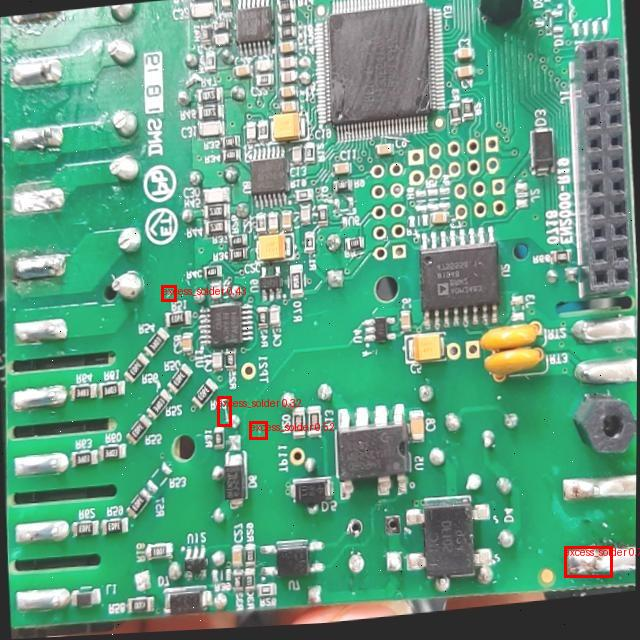

In [3]:
from IPython.display import display, Image
display(Image(filename=str(ROOT/'outputs/baseline'/(image.stem+'_annotated.jpg'))))

## 4. 검증 데이터로 점수 확인
임계값 조정은 val, 최종 확인은 test로 합니다.

In [7]:
baseline_report=detection_eval(ROOT/'models/best.pt', 'original', 'val', DEVICE)
print(baseline_report)

Ultralytics 8.4.215  Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8124MiB)
YOLO26m summary (fused): 130 layers, 20,356,391 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 805.6±243.4 MB/s, size: 59.6 KB)
val: Scanning C:\Project\AI_Source\jahwa\data\final_solder\labels\val... 687 images, 433 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 687/687 2.6Kit/s 0.3s0.1ss
val: New cache created: C:\Project\AI_Source\jahwa\data\final_solder\labels\val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 172/172 3.7it/s 46.4s0.3ss
                   all        687        734      0.911      0.915      0.911      0.635
   insufficient_solder         43        187      0.929      0.983      0.969      0.601
         excess_solder         56        111       0.96      0.937      0.945       0.63
         solder_bridge         56        181       0.96      0.935      0.943   

In [4]:
from pcb4_transfer import image_predictions, choose_threshold, classification_metrics, write_json
baseline_image_val=image_predictions(ROOT/'models/best.pt', 'val', DEVICE, domain='original')
baseline_original_threshold=choose_threshold(baseline_image_val)
baseline_image_metrics=classification_metrics(baseline_image_val, baseline_original_threshold)
write_json(ROOT/'outputs/evaluation/baseline_original_image_val.json', {'threshold':baseline_original_threshold,'metrics':baseline_image_metrics,'predictions':baseline_image_val})
print(baseline_image_metrics)

{'TP': 248, 'FP': 3, 'TN': 430, 'FN': 6, 'accuracy': 0.9868995633187773, 'precision': 0.9880478087649402, 'recall': 0.9763779527559056, 'f1': 0.9821782178217822, 'roc_auc': 0.9966812751177465, 'average_precision': 0.995405962212945, 'false_positive_rate': 0.006928406466512702, 'defect_inflow_reduction': 97.63779527559055}


In [12]:
# 원본 validation에서 실제로 발생한 Baseline 정상 오검출 시각화
folder=ROOT/'outputs/baseline/original_val_false_positives'
folder.mkdir(parents=True,exist_ok=True)
false_positives=[r for r in baseline_image_val if r['y_true']==0 and r['defect_score']>=baseline_original_threshold]
for row in false_positives:
    prediction=inspector.model.predict(row['path'],imgsz=800,conf=baseline_original_threshold,iou=.45,max_det=300,device=DEVICE,verbose=False)[0]
    prediction.save(filename=str(folder/row['image_id']))
write_json(folder/'cases.json',{'split':'val','model':'models/best.pt','threshold':baseline_original_threshold,'cases':false_positives})
print('Actual original-val FP images:',len(false_positives))

Actual original-val FP images: 3


Cross-domain duplicate check: []


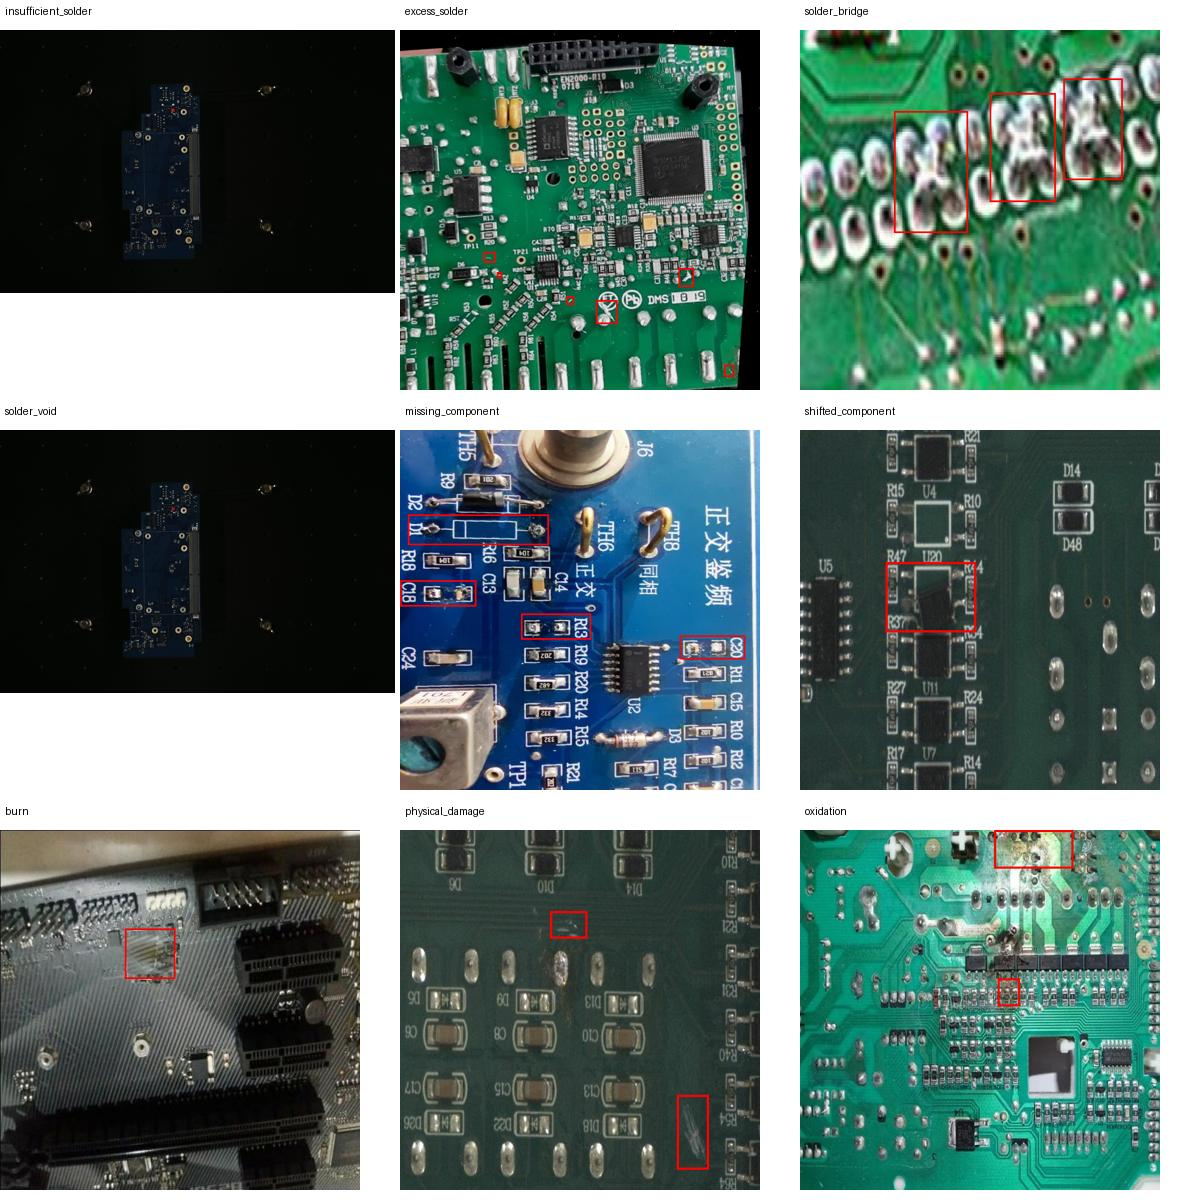

In [10]:
# 라벨 시각화 및 두 데이터 도메인 사이의 정확한 중복까지 확인
import importlib, pcb4_transfer
importlib.reload(pcb4_transfer)
audit=pcb4_transfer.audit_and_eda()
assert not audit['cross_domain_exact_duplicates']
print('Cross-domain duplicate check:', audit['cross_domain_exact_duplicates'])
display(Image(filename=str(ROOT/'outputs/eda/original_class_policy_examples.jpg')))

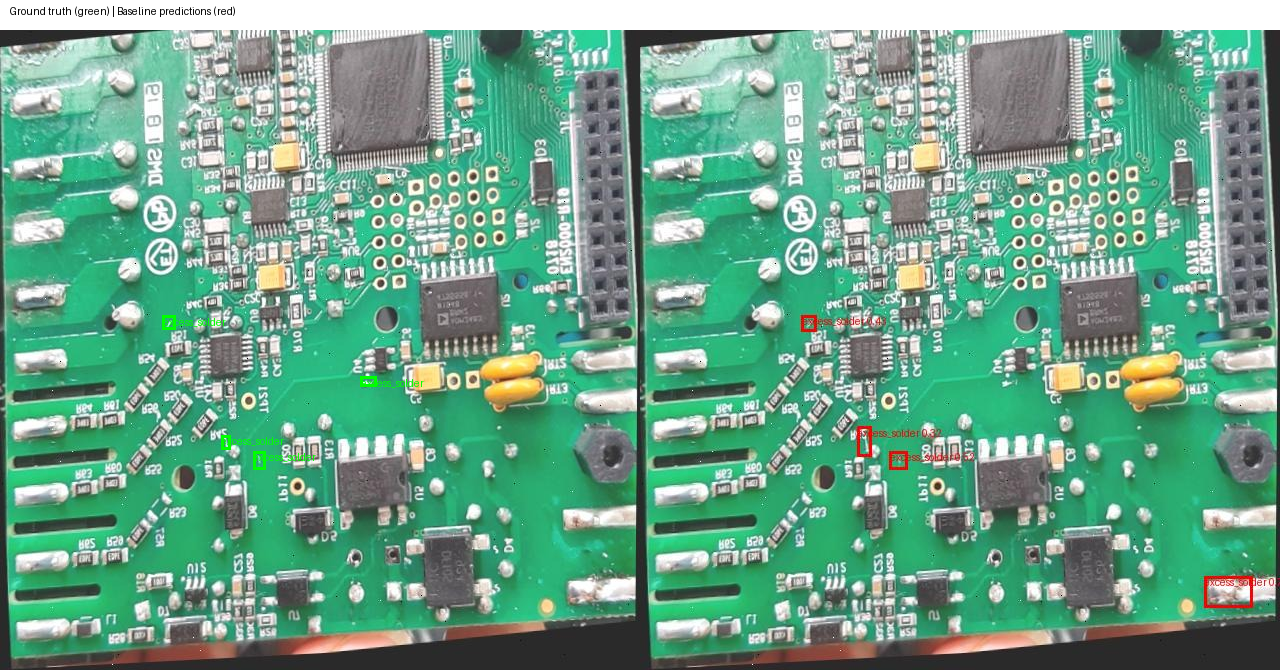

In [6]:
from PIL import Image as PILImage, ImageDraw, ImageOps
with PILImage.open(image) as source: gt=source.convert('RGB')
w,h=gt.size
draw=ImageDraw.Draw(gt)
label=ROOT/'data/final_solder/labels/val'/(image.stem+'.txt')
for line in label.read_text().splitlines():
    cls,x,y,bw,bh=map(float,line.split())
    draw.rectangle([(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h],outline='lime',width=3)
    draw.text(((x-bw/2)*w,(y-bh/2)*h),inspector.model.names[int(cls)],fill='lime')
canvas=PILImage.new('RGB',(1280,670),'white')
canvas.paste(ImageOps.contain(gt,(640,640)),(0,30))
with PILImage.open(ROOT/'outputs/baseline'/(image.stem+'_annotated.jpg')) as pred: canvas.paste(ImageOps.contain(pred,(640,640)),(640,30))
ImageDraw.Draw(canvas).text((10,5),'Ground truth (green) | Baseline predictions (red)',fill='black')
canvas.save(ROOT/'outputs/baseline/ground_truth_vs_prediction.jpg')
display(canvas)

In [13]:
# 계산·통합 코드 검증: 아래 4행은 단위 테스트이며 실제 성능 산출물에 넣지 않습니다.
import ast
from pcb4_transfer import classification_metrics
for filename in ['pcb4_transfer.py','inspect_pcb.py','integration.py','app.py']:
    ast.parse((ROOT/filename).read_text(encoding='utf-8'))
probe=[{'y_true':y,'defect_score':s} for y,s in [(1,.9),(1,.1),(0,.8),(0,.2)]]
m=classification_metrics(probe,.5)
assert [m[k] for k in ['TP','FP','TN','FN']]==[1,1,1,1]
assert m['defect_inflow_reduction']==50
from integration import combine_team_results
assert combine_team_results([{'part_type':'PCB','status':'OK'}])['status']=='REVIEW'
assert combine_team_results([{'part_type':p,'status':'OK'} for p in ['Lens','Ring','PCB']])['status']=='OK'
try:
    combine_team_results([{'part_type':'PCB','status':'OK'}]*2)
    raise AssertionError('duplicate must fail')
except ValueError:
    pass
print('Syntax / metrics / team contract tests PASS')

Syntax / metrics / team contract tests PASS
